## 1. Trigonometric Harmonic Signal + Additive Gaussian Noise
- Models physical periodic signals (e.g., audio waves, AC current, cyclical seasonal trends) obscured by Gaussian (Normal) white noise. 
- It demonstrates how to combine pure deterministic sine/cosine waves with zero-mean normal error distributions.

### Mathematical Formula
The pure functional signal $y_{\text{pure}}(t)$ and noisy population $y_{\text{noisy}}(t)$ are defined as:

$$y_{\text{pure}}(t) = A \cdot \sin(2\pi f t + \phi)$$

$$y_{\text{noisy}}(t) = y_{\text{pure}}(t) + \epsilon, \quad \epsilon \sim \mathcal{N}(\mu, \sigma^2)$$

**Pronunciation & Symbol Guide:**
* $A$: Signal amplitude (*A*).
* $f$: Frequency in Hertz / cycles per unit time (*f*).
* $\phi$: Phase shift angle (*phi*).
* $\epsilon$: Random additive noise perturbation (*epsilon*).
* $\mathcal{N}(\mu, \sigma^2)$: Normal distribution with mean $\mu$ and standard deviation $\sigma$.



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use(
    'seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default'
)
plt.rcParams['figure.dpi'] = 100 
np.random.seed(seed=42)

=== 1. HARMONIC SIGNAL + GAUSSIAN NOISE ===
Time Domain Array Length: 200
Signal Range (Pure): [-3.00, 3.00]
Signal Range (Noisy): [-3.74, 4.35]
Calculated Noise Variance: 0.3861



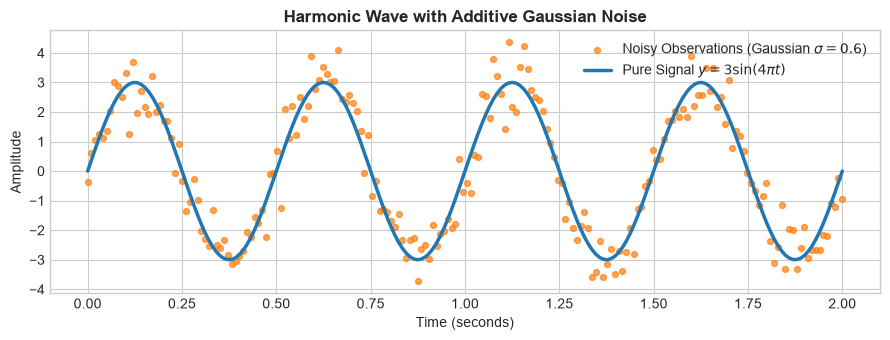

In [ ]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
t = np.linspace(
    start=0.0,  # Start interval boundary in seconds
    stop=2.0,   # Stop interval boundary (2 seconds duration)
    num=200     # Total evenly spaced sample points
)
f = 2.0  # Frequency = 2 Hz
A = 3.0  # Amplitude = 3.0
phi = 0.0
y_pure = A * np.sin(2 * np.pi * f  * t + phi)

gaussian_noise = np.random.normal(
    loc=0.0,      # Mean (centre) of the Gaussian distribution
    scale=0.6,    # Standard deviation (spread / noise intensity)
    size=len(t)   # Number of random samples generated matching time array shape
)
y_noisy = y_pure + gaussian_noise

print("=== 1. HARMONIC SIGNAL + GAUSSIAN NOISE ===")
print(f"Time Domain Array Length: {len(t)}")
print(f"Signal Range (Pure): [{y_pure.min():.2f}, {y_pure.max():.2f}]")
print(f"Signal Range (Noisy): [{y_noisy.min():.2f}, {y_noisy.max():.2f}]")
print(f"Calculated Noise Variance: {np.var(a=gaussian_noise):.4f}\n")

# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(
    figsize=(9, 3.5)  # Width and height of the figure in inches
)

# Noisy Observations (Scatter Plot)
plt.scatter(
    x=t,                                                   # X-coordinates (time values)
    y=y_noisy,                                             # Y-coordinates (noisy signal values)
    color='#ff7f0e',                                       # Safety orange marker color
    s=18,                                                  # Marker area size in points squared
    alpha=0.7,                                             # Marker opacity (0.0 translucent to 1.0 opaque)
    zorder=2,                                              # Layer drawing order (lower values rendered below)
    label='Noisy Observations (Gaussian $\\sigma=0.6$)'     # Legend label entry
)

# Pure Underlying Signal (Line Plot)
plt.plot(
    t,                                                     # X-axis sequence (time values)
    y_pure,                                                # Y-axis sequence (clean signal values)
    color='#1f77b4',                                       # Standard dark blue line color
    linewidth=2.5,                                         # Thickness of the plot line
    zorder=3,                                              # Drawn on top of scatter points
    label='Pure Signal $y = 3\\sin(4\\pi t)$'               # Legend label entry
)

plt.title(
    label='Harmonic Wave with Additive Gaussian Noise',    # Figure title text
    fontsize=12,                                           # Title font size in points
    fontweight='bold'                                      # Bold typography for title visual prominence
)
plt.xlabel(xlabel='Time (seconds)')                       # X-axis label text
plt.ylabel(ylabel='Amplitude')                            # Y-axis label text
plt.legend(loc='upper right')                             # Corner anchor position for legend box
plt.tight_layout()                                        # Automatically adjusts subplots to fit figure area
plt.show()

## 2. Exponential Decay + Uniform Measurement Error

### Overview & Purpose
Simulates physical decay dynamics (e.g., radioactive decay, capacitor discharge, thermal cooling) subjected to bounded quantization or sensor tolerance error modeled by a Uniform distribution.

### Mathematical Formula
Given initial value $N_0$ and decay constant $\lambda$:

$$y_{\text{decay}}(t) = N_0 \cdot e^{-\lambda t}$$

$$y_{\text{measured}}(t) = y_{\text{decay}}(t) + u, \quad u \sim \mathcal{U}(-w, +w)$$

**Pronunciation & Symbol Guide:**
* $N_0$: Initial concentration/quantity at $t=0$ (*N sub zero*).
* $\lambda$: Decay rate parameter (*lambda*).
* $u$: Bounded uniform noise variable (*u*).
* $\mathcal{U}(-w, +w)$: Continuous uniform distribution bounded between $-w$ and $+w$.

=== 2. EXPONENTIAL DECAY + UNIFORM ERROR ===
Initial Pure Value at t=0: 10.00
Final Pure Value at t=5: 0.1832
Uniform Error Bounds: [-0.4874, 0.4850]



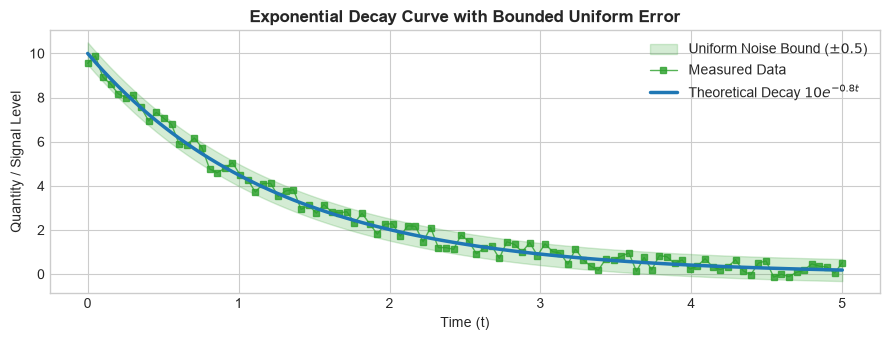

In [28]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
t_decay = np.linspace(
    start=0.0,  # Start of time interval
    stop=5.0,   # End of time interval (5 seconds duration)
    num=100     # Total number of generated evaluation steps
)
N0 = 10.0          # Initial amplitude
decay_rate = 0.8   # Decay constant lambda

y_decay_pure = N0 * np.exp(-decay_rate * t_decay)

uniform_noise = np.random.uniform(
    low  = -0.5,         # Lower boundary of error sampling range
    high = 0.5,         # Upper boundary of error sampling range
    size=len(t_decay) # Output array length matching domain grid size
)
y_decay_measured = y_decay_pure + uniform_noise

print("=== 2. EXPONENTIAL DECAY + UNIFORM ERROR ===")
print(f"Initial Pure Value at t=0: {y_decay_pure[0]:.2f}")
print(f"Final Pure Value at t=5: {y_decay_pure[-1]:.4f}")
print(f"Uniform Error Bounds: [{uniform_noise.min():.4f}, {uniform_noise.max():.4f}]\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(
    figsize=(9, 3.5)  # Width and height of plot window in inches
)

# Bounded noise band visualization (shaded envelope)
plt.fill_between(
    x=t_decay,                                              # X-axis time coordinates
    y1=y_decay_pure - 0.5,                                 # Lower bound curve of noise window
    y2=y_decay_pure + 0.5,                                 # Upper bound curve of noise window
    color='#2ca02c',                                        # Forest green envelope shading color
    alpha=0.2,                                              # Soft translucent transparency factor
    label='Uniform Noise Bound ($\\pm 0.5$)'                  # Legend description entry
)

# Plotting measured samples
plt.plot(
    t_decay,                                                # X-coordinates (time values)
    y_decay_measured,                                       # Y-coordinates (measured noisy signal values)
    's-',                                                   # Marker & line style format (square markers with solid line)
    color='#2ca02c',                                        # Forest green line color
    linewidth=1,                                            # Thickness of connecting line
    markersize=4,                                           # Vertex square marker side dimension
    alpha=0.8,                                              # Line opacity
    label='Measured Data'                                   # Legend label entry
)
plt.plot(
    t_decay,                                                # X-coordinates (time values)
    y_decay_pure,                                           # Y-coordinates (pure theoretical decay curve)
    color='#1f77b4',                                        # Dark blue color
    linewidth=2.5,                                          # Line thickness for ground truth curve
    label='Theoretical Decay $10 e^{-0.8t}$'                # Legend entry with LaTeX equation
)

plt.title(
    label='Exponential Decay Curve with Bounded Uniform Error',  # Plot title
    fontsize=12,                                                # Title text font size
    fontweight='bold'                                           # Bold title font weight
)
plt.xlabel(xlabel='Time (t)')                               # X-axis domain title
plt.ylabel(ylabel='Quantity / Signal Level')                # Y-axis range title
plt.legend(loc='upper right')                             # Position legend in upper right corner
plt.tight_layout()                                        # Optimize plot margin spacing
plt.show()

[1.10989469 4.47055544 4.60358271 8.6456361  5.4664822  3.80400549
 9.76800329 1.10720593 4.22548428 0.42024675]
[ 0.1991882   0.11429981  0.42567109 -0.26129182  0.30786348 -0.15572801
  0.44328629  0.36922049 -0.56126322  0.65158927]


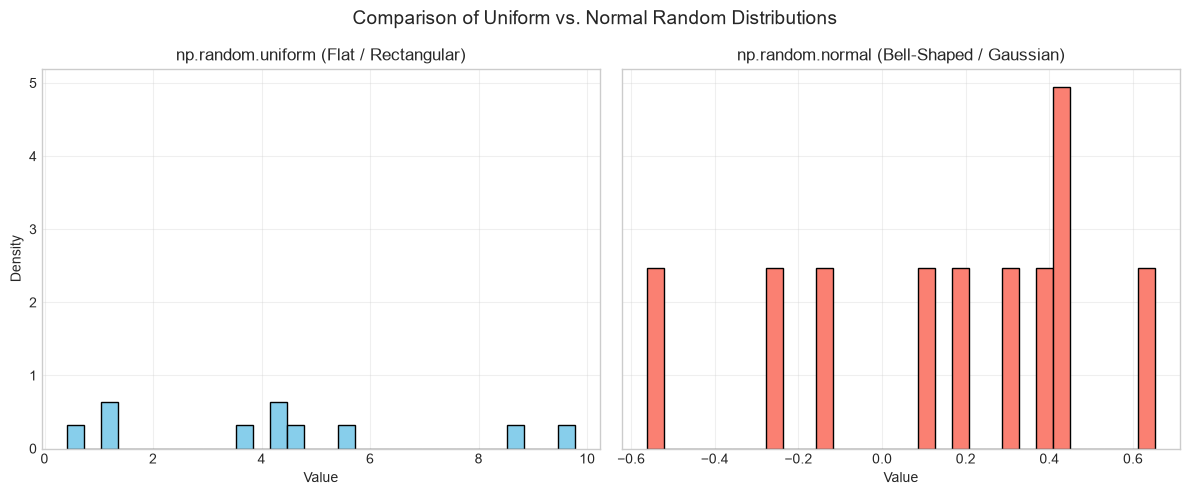

In [32]:
import numpy as np
uniform_data = np.random.uniform(low = 0.0, high=10.0, size=10)
print(uniform_data)

normal_data = np.random.normal(
    loc=0.0,      # Mean (centre) of the Gaussian distribution
    scale=0.6,    # Standard deviation (spread / noise intensity)
    size=10   # Number of random samples generated matching time array shape
)
print(normal_data)

# 2. Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot Uniform Distribution
ax1.hist(uniform_data, bins=30, color='skyblue', edgecolor='black', density=True)
ax1.set_title('np.random.uniform (Flat / Rectangular)')
ax1.set_xlabel('Value')
ax1.set_ylabel('Density')
ax1.grid(True, alpha=0.3)

# Plot Normal Distribution
ax2.hist(normal_data, bins=30, color='salmon', edgecolor='black', density=True)
ax2.set_title('np.random.normal (Bell-Shaped / Gaussian)')
ax2.set_xlabel('Value')
ax2.grid(True, alpha=0.3)

plt.suptitle('Comparison of Uniform vs. Normal Random Distributions', fontsize=14)
plt.tight_layout()
plt.show()

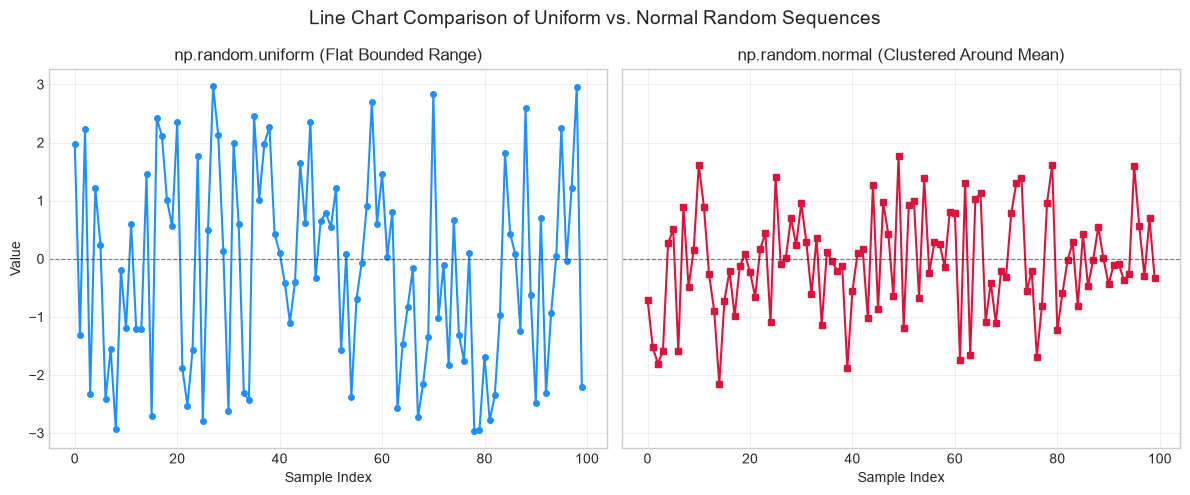

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate sequential data for both distributions (fewer points for a clean line chart)
n_points = 100
x = np.arange(n_points)

# Uniform: values spread evenly between -3 and 3
uniform_data = np.random.uniform(low=-3.0, high=3.0, size=n_points)

# Normal: values clustered around mean 0 with standard deviation 1
normal_data = np.random.normal(loc=0.0, scale=1.0, size=n_points)

# 2. Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot Uniform Distribution Line Chart
ax1.plot(x, uniform_data, color='dodgerblue', marker='o', markersize=4, linestyle='-', linewidth=1.5)
ax1.set_title('np.random.uniform (Flat Bounded Range)')
ax1.set_xlabel('Sample Index')
ax1.set_ylabel('Value')
ax1.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax1.grid(True, alpha=0.3)

# Plot Normal Distribution Line Chart
ax2.plot(x, normal_data, color='crimson', marker='s', markersize=4, linestyle='-', linewidth=1.5)
ax2.set_title('np.random.normal (Clustered Around Mean)')
ax2.set_xlabel('Sample Index')
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.grid(True, alpha=0.3)

plt.suptitle('Line Chart Comparison of Uniform vs. Normal Random Sequences', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Polynomial Function + Sparse Outliers (Salt & Pepper / Impulse Noise)

- Models smooth polynomial trends contaminated by severe intermittent sensor corruptions, dropped packets, or hardware glitches (Impulse or Salt & Pepper noise). 
- Demonstrates how sparse extreme values alter dataset statistics.

### Mathematical Formula
Given a cubic polynomial curve $p(x)$:

$$p(x) = a_3 x^3 + a_2 x^2 + a_1 x + a_0$$

Outliers are injected into a random subset of indices $I_{\text{outlier}} \subset \{0, 1, \dots, N-1\}$:

$$y_{\text{corrupted}}[i] = \begin{cases} p(x_i) + \eta_i, & \text{if } i \in I_{\text{outlier}} \quad (\eta_i \text{ is a large spike}) \\ p(x_i), & \text{otherwise} \end{cases}$$


**Pronunciation & Symbol Guide:**
* $p(x)$: Deterministic polynomial function (*p of x*).
* $I_{\text{outlier}}$: Index set chosen for outlier injection (*outlier index set*).
* $\eta_i$: High-amplitude spike value (*eta sub i*).

=== 3. POLYNOMIAL + IMPULSE OUTLIERS ===
Total Data Points: 120
Injected Outlier Count: 9
Outlier Indices: [ 49 104  27  68  25 105 110 115  81]
Clean Data Mean: 0.6443 | Corrupted Data Mean: 0.7365



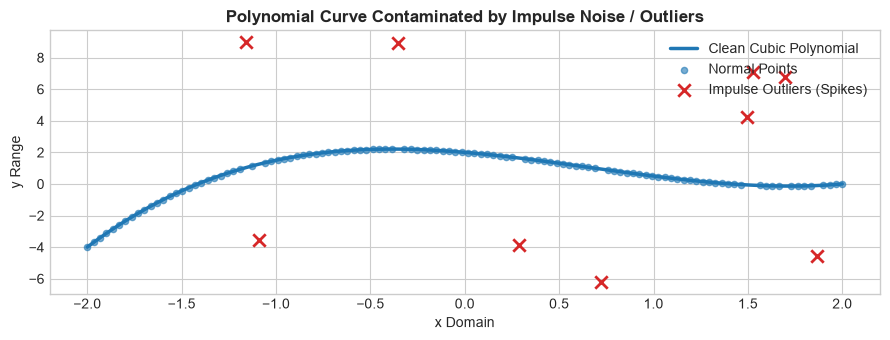

In [61]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
x_poly = np.linspace(
    start=-2.0,  # Lower domain boundary
    stop=2.0,    # Upper domain boundary
    num=120      # Total grid point resolution count
)

# Cubic Polynomial: p(x) = 0.5*x^3 - x^2 - x + 2
y_poly_clean = 0.5 * (x_poly**3) - (x_poly**2) - x_poly + 2.0
y_poly_corrupted = y_poly_clean.copy()
# Select 8% of indices randomly to inject impulse spikes
num_outliers = int(0.08 * len(x_poly))

outlier_indices = np.random.choice(
    a=len(x_poly),         # Sampling population size index range
    size=num_outliers,     # Total number of outlier positions to select
    replace=False          # Sample without replacement to avoid duplicate indices
)


# Inject random positive and negative spikes
spike_directions = np.random.choice(
    a=[-1, 1],             # Binary sign options (+1 for positive spike, -1 for negative spike)
    size=num_outliers      # Matching outlier count
)


spike_magnitudes = np.random.uniform(
    low=4.0,               # Minimum impulse spike amplitude
    high=8.0,              # Maximum impulse spike amplitude
    size=num_outliers      # Quantity of generated spike scales
)


spikes = spike_directions * spike_magnitudes

y_poly_corrupted[outlier_indices] += spikes

print("=== 3. POLYNOMIAL + IMPULSE OUTLIERS ===")
print(f"Total Data Points: {len(x_poly)}")
print(f"Injected Outlier Count: {num_outliers}")
print(f"Outlier Indices: {outlier_indices}")
print(f"Clean Data Mean: {y_poly_clean.mean():.4f} | Corrupted Data Mean: {y_poly_corrupted.mean():.4f}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(
    figsize=(9, 3.5)  # Figure dimension configuration in inches
)

# Clean polynomial curve
plt.plot(
    x_poly,                                                      # Domain coordinates
    y_poly_clean,                                                # Uncorrupted polynomial curve points
    color='#1f77b4',                                             # Dark blue line color
    linewidth=2.5,                                               # Line stroke width
    zorder=2,                                                    # Layer ordering
    label='Clean Cubic Polynomial'                               # Legend text
)

# Uncorrupted points (regular observations)
normal_mask = np.ones(
    shape=len(x_poly),                                           # Mask shape matching array size
    dtype=bool                                                   # Boolean mask data type
)
normal_mask[outlier_indices] = False
plt.scatter(
    x=x_poly[normal_mask],                                       # Domain points for clean subset
    y=y_poly_corrupted[normal_mask],                             # Corresponding clean response values
    color='#1f77b4',                                             # Blue dot marker color
    s=20,                                                        # Dot marker size
    alpha=0.6,                                                   # Marker opacity
    label='Normal Points'                                        # Legend title
)

# Outlier spikes (highlighted in red)
plt.scatter(
    x=x_poly[outlier_indices],                                   # Outlier X-coordinates
    y=y_poly_corrupted[outlier_indices],                         # Outlier corrupted Y-values
    color='#d62728',                                             # Crimson red color for immediate visual detection
    marker='x',                                                  # Cross symbol marker representation
    s=80,                                                        # Enlarged marker size
    linewidth=2,                                                 # Cross symbol line stroke width
    zorder=4,                                                    # Top visual layer priority
    label='Impulse Outliers (Spikes)'                            # Legend label
)

plt.title(
    label='Polynomial Curve Contaminated by Impulse Noise / Outliers', # Title string
    fontsize=12,                                                       # Font size
    fontweight='bold'                                                  # Bold weight
)
plt.xlabel(xlabel='x Domain')                                    # X-axis label
plt.ylabel(ylabel='y Range')                                     # Y-axis label
plt.legend(loc='upper right')                                    # Legend location
plt.tight_layout()                                               # Optimize subplot alignment
plt.show()

In [ ]:
import numpy as np
arr1 = np.arange(10,101,10)
print(arr1)

lst_sub = np.random.choice(10,3,replace=False)
print(lst_sub)
arr1[lst_sub]+=100
print(arr1)

# anantharamansubaraman

[ 10  20  30  40  50  60  70  80  90 100]
[2 7 0]
[110  20 130  40  50  60  70 180  90 100]


## 4. Multi-Component Composite Signal + Heteroscedastic Noise
- Generates complex real-world signals consisting of a linear trend, multiple oscillating frequencies, and **heteroscedastic noise** (where noise variance increases dynamically over time, common in financial volatility and expanding drift sensors).

### Mathematical Formula
The composite functional signal $S(t)$ combines linear trend and two sine components:

$$S(t) = (m \cdot t + c) + A_1 \sin(2\pi f_1 t) + A_2 \sin(2\pi f_2 t)$$

Heteroscedastic noise standard deviation $\sigma(t)$ expands proportionally with $t$:

$$\sigma(t) = \sigma_0 + \gamma \cdot t, \quad y_{\text{composite}}(t) = S(t) + \mathcal{N}(0, \sigma(t)^2)$$

**Pronunciation & Symbol Guide:**
* $m$: Linear trend slope (*m*).
* $f_1, f_2$: Primary and secondary harmonic frequencies (*f sub 1, f sub 2*).
* $\sigma(t)$: Time-varying standard deviation (*sigma of t*).
* $\gamma$: Noise expansion rate coefficient (*gamma*).
* $A_1$ and $A_2$ are the Amplitudes of two distinct sinusoidal waves (cycles or periodic components).
* $c$: Baseline offset / $y$-intercept at $t=0$

=== 4. COMPOSITE SIGNAL + HETEROSCEDASTIC NOISE ===
Initial Noise Std Dev (t=0): 0.10
Final Noise Std Dev (t=10): 1.10
Overall Composite Signal Length: 300



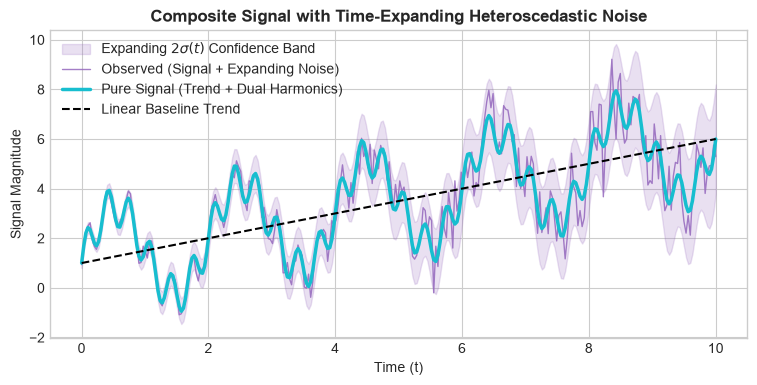

In [63]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
t_comp = np.linspace(
    start=0.0,  # Start time in seconds
    stop=10.0,  # Stop time in seconds (10 second window)
    num=300     # Evaluation step count
)

# Component 1: Linear upward trend (m=0.5, c=1.0)
trend = 0.5 * t_comp + 1.0

# Component 2 & 3: Dual-frequency harmonics (0.5 Hz low freq + 3.0 Hz high freq)
harmonics = 2.0 * np.sin(2 * np.pi * 0.5 * t_comp) + 0.8 * np.sin(2 * np.pi * 3.0 * t_comp)

S_pure = trend + harmonics

# Time-dependent standard deviation: sigma grows from 0.1 at t=0 to 1.1 at t=10
sigma_t = 0.1 + 0.1 * t_comp
hetero_noise = np.random.normal(
    loc=0.0,           # Zero mean base noise distribution
    scale=1.0,         # Standard unit normal standard deviation
    size=len(t_comp)   # Sample size matching domain array length
) * sigma_t
y_composite = S_pure + hetero_noise

print("=== 4. COMPOSITE SIGNAL + HETEROSCEDASTIC NOISE ===")
print(f"Initial Noise Std Dev (t=0): {sigma_t[0]:.2f}")
print(f"Final Noise Std Dev (t=10): {sigma_t[-1]:.2f}")
print(f"Overall Composite Signal Length: {len(y_composite)}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(
    figsize=(9, 4)  # Width and height of canvas frame in inches
)

# Time-expanding error region visual
plt.fill_between(
    x=t_comp,                                                      # Time axis coordinates
    y1=S_pure - 2 * sigma_t,                                      # Lower 2-sigma lower envelope threshold
    y2=S_pure + 2 * sigma_t,                                      # Upper 2-sigma upper envelope threshold
    color='#9467bd',                                               # Soft purple fill color
    alpha=0.2,                                                     # Envelope translucent shading factor
    label='Expanding $2\\sigma(t)$ Confidence Band'                 # Legend label
)

# Observed composite series plot
plt.plot(
    t_comp,                                                        # Time grid
    y_composite,                                                   # Signal + heteroscedastic noise observations
    color='#9467bd',                                               # Muted purple line color
    linewidth=1.0,                                                 # Thin line for noisy signal details
    alpha=0.85,                                                    # Translucency level
    label='Observed (Signal + Expanding Noise)'                    # Legend text
)
plt.plot(
    t_comp,                                                        # Time grid
    S_pure,                                                        # Pure combined signal values
    color='#17becf',                                               # Cyan line color
    linewidth=2.5,                                                 # Line stroke thickness
    label='Pure Signal (Trend + Dual Harmonics)'                  # Legend text
)
plt.plot(
    t_comp,                                                        # Time grid
    trend,                                                         # Trend line component
    'k--',                                                         # Black dashed line format
    linewidth=1.5,                                                 # Dashed line thickness
    label='Linear Baseline Trend'                                  # Legend entry
)

plt.title(
    label='Composite Signal with Time-Expanding Heteroscedastic Noise', # Title
    fontsize=12,                                                        # Font size
    fontweight='bold'                                                   # Bold title font style
)
plt.xlabel(xlabel='Time (t)')                                       # X-axis label
plt.ylabel(ylabel='Signal Magnitude')                               # Y-axis label
plt.legend(loc='upper left')                                        # Top left legend positioning